# Measure how far definitions diverge, with DefScore

Draw how similar the definitions of one term are across papers. This uses only MBDef-Gold's **relevant, hand-labelled records**, pooled across its three paper-disjoint splits: human annotation gives a cleaner view of conceptual variation than automatic extraction would, because extraction errors cannot add to it. This is description, not training or evaluation of an extractor.

## Load MBDef-Gold
`load_gold()` reads MBDef-Gold's three split files from `$DATA_ROOT/MBDef-Gold/data/`, where `uv run mbdef data fetch MBDef-Gold/` puts them, into one polars DataFrame; its `split` column says train, dev or test. MBDef-Gold's paper ids are its own; they do not join with MBDef's.

In [1]:
import json
from pathlib import Path

from mbdef.analysis import load_gold

OUTPUTS = Path("outputs")  # tutorials/outputs/, not tracked by git
gold = load_gold()
print(gold.group_by("split", "relevant").len().sort("split", "relevant"))

shape: (6, 3)
┌───────┬──────────┬─────┐
│ split ┆ relevant ┆ len │
│ ---   ┆ ---      ┆ --- │
│ str   ┆ bool     ┆ u32 │
╞═══════╪══════════╪═════╡
│ dev   ┆ false    ┆ 179 │
│ dev   ┆ true     ┆ 101 │
│ test  ┆ false    ┆ 318 │
│ test  ┆ true     ┆ 310 │
│ train ┆ false    ┆ 828 │
│ train ┆ true     ┆ 592 │
└───────┴──────────┴─────┘


## The pairs
Terms are matched by case, spacing and outer punctuation only; synonyms and plurals are not merged. Every non-empty definition of a relevant record counts, with no language or length filter.

Three groups of pairs are compared: all same-term pairs across papers, all same-term pairs within a paper, and 2,000 pairs of different terms from different papers drawn uniformly (seed 0). The last two are reference distributions; pairs of different terms are not negative labels.

In [2]:
from mbdef.analysis.divergence import build_pairs, definitions

rows = definitions(gold)
groups = build_pairs(rows, 2000)
print("Relevant definitions:", len(rows))
print("Papers:", len({row["paper_id"] for row in rows}))
print({name: len(pairs) for name, pairs in groups.items()})

Relevant definitions: 1192
Papers: 130
{'cross_paper': 1395, 'same_paper': 398, 'different_term': 2000}


## Score the pairs and draw the figure
DefScore ([docs/step-3-extraction/evaluate.md](../docs/step-3-extraction/evaluate.md)) is the mean of word-overlap F1, the cosine of `BAAI/bge-base-en-v1.5` vectors and the entailment probability of `tasksource/ModernBERT-large-nli` in both directions, calibrated as `clip(1.4028410596332237 × mean − 0.2973741431607951, 0, 1)`. The scorer and the pinned model revisions are the pipeline's own (`mbdef.evaluate.metric`); nothing is refitted.

The models download on first use (several GB); a GPU is used when there is one, and on a CPU the scoring takes a while. Scores are saved as they are made, so an interrupted run resumes.

1192 definitions; 3793 pairs; 3793 to score


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/174 [00:00<?, ?it/s]

Scored 512/3793 missing pairs


Scored 1024/3793 missing pairs


Scored 1536/3793 missing pairs


... (2 outputs left out)

Scored 3072/3793 missing pairs


Scored 3584/3793 missing pairs


Scored 3793/3793 missing pairs


{
  "cross_paper": {
    "n": 1395,
    "mean": 0.23292563630358445,
    "median": 0.20823681533213861,
    "q1": 0.11371950754917157,
    "q3": 0.3188927841324537,
    "share_below_0_5": 0.9383512544802868,
    "mean_ci95_term_bootstrap": [
      0.178345972105356,
      0.2533753848811731
    ],
    "bootstrap_terms": 71,
    "term_balanced_mean": 0.20466936023411086
  },
  "same_paper": {
    "n": 398,
    "mean": 0.2596463515104141,
    "median": 0.2219296089089169,
    "q1": 0.12928903761898836,
    "q3": 0.34520242445779165,
    "share_below_0_5": 0.8944723618090452,
    "mean_ci95_term_bootstrap": [
      0.2401559164956897,
      0.29918916612107876
    ],
    "bootstrap_terms": 95,
    "term_balanced_mean": 0.30344187870458256
  },
  "different_term": {
    "n": 2000,
    "mean": 0.032095866320043055,
    "median": 0.012174952451546067,
    "q1": 0.0,
    "q3": 0.05183160026365323,
    "share_below_0_5": 1.0
  }
}


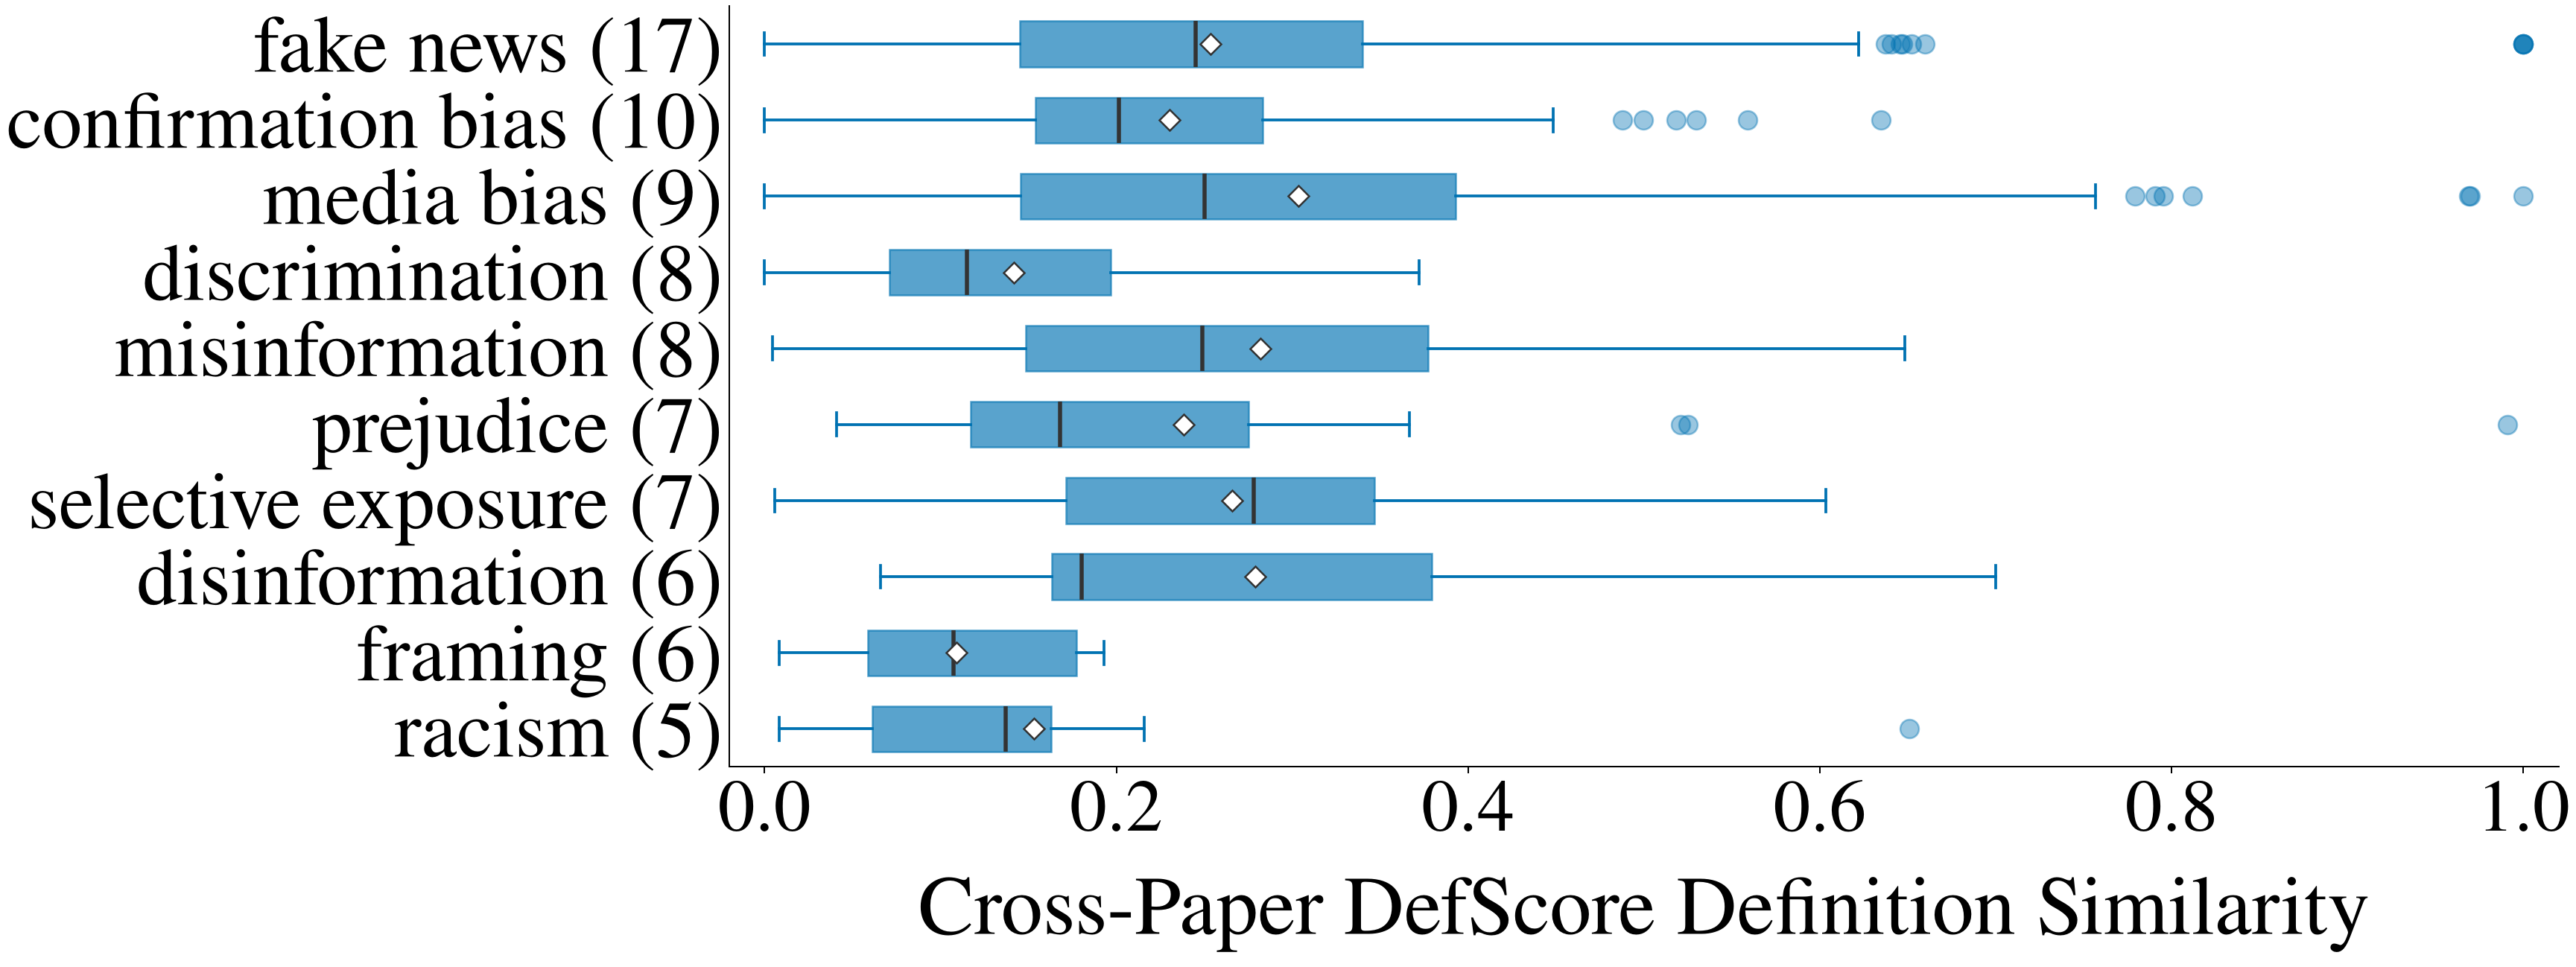

In [3]:
from IPython.display import Image, display

from mbdef.analysis.divergence import run

divergence_output = OUTPUTS / "definitional-divergence"
report = run(gold, divergence_output, baseline_pairs=2000)
print(json.dumps(report["groups"], indent=2))
display(Image(filename=str(divergence_output / "definitional-divergence.png")))